In [3]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import requests

file_path_trips = "./microcensus_filter/microcensus_ne_weekday_trips.csv"
file_path_etappen = "./microcensus/dataset/etappen.csv"

# Global session for gjenbruk av TCP-forbindelser
session = requests.Session()


def fetch_height(coord):
    """Henter høyde for et enkelt koordinatpar (easting, northing)."""
    easting, northing = coord
    if pd.isna(easting) or pd.isna(northing):
        return coord, None
    url = f"https://api3.geo.admin.ch/rest/services/height?easting={easting}&northing={northing}&sr=21781"
    try:
        response = session.get(url, timeout=10)
        return coord, float(response.json()["height"])
    except Exception as e:
        print(f"Feil ved henting for {coord}: {e}")
        return coord, None


# 1. Les inn data
trips_df = pd.read_csv(file_path_trips)
etappen_df = pd.read_csv(file_path_etappen, encoding="latin1")
etappen_df = etappen_df.merge(
    trips_df[["HHNR", "WEGNR"]], 
    on=["HHNR", "WEGNR"],
    how="right",
)

# 2. Samle ALLE unike koordinatpar fra begge dataframes
unique_coords = set(zip(trips_df["S_X_CH1903"], trips_df["S_Y_CH1903"])).union(
    set(zip(trips_df["Z_X_CH1903"], trips_df["Z_Y_CH1903"])),
    set(zip(etappen_df["S_X_CH1903"], etappen_df["S_Y_CH1903"])),
    set(zip(etappen_df["Z_X_CH1903"], etappen_df["Z_Y_CH1903"])),
)

print(f"Totalt antall unike koordinater å hente: {len(unique_coords)}")

# 3. Hent høyder i parallell med tråder (f.eks. 20 samtidige tråder)
height_map = {}
with ThreadPoolExecutor(max_workers=20) as executor:
    results = executor.map(fetch_height, unique_coords)
    for coord, height in results:
        height_map[coord] = height

# 4. Map resultatene tilbake på dataframene
trips_df["S_Z_CH1903"] = [
    height_map.get((x, y))
    for x, y in zip(trips_df["S_X_CH1903"], trips_df["S_Y_CH1903"])
]
trips_df["Z_Z_CH1903"] = [
    height_map.get((x, y))
    for x, y in zip(trips_df["Z_X_CH1903"], trips_df["Z_Y_CH1903"])
]

etappen_df["S_Z_CH1903"] = [
    height_map.get((x, y))
    for x, y in zip(etappen_df["S_X_CH1903"], etappen_df["S_Y_CH1903"])
]
etappen_df["Z_Z_CH1903"] = [
    height_map.get((x, y))
    for x, y in zip(etappen_df["Z_X_CH1903"], etappen_df["Z_Y_CH1903"])
]

# 5. Lagre resultatene permanent
trips_df.to_csv(file_path_trips, index=False)
etappen_df.to_csv(file_path_etappen, index=False, encoding="latin1")

print("Ferdig! Høyder er beregnet og lagret.")

Totalt antall unike koordinater å hente: 3723


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_72534/3944408819.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  trips_df["S_Z_CH1903"] = [
/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_72534/3944408819.py:56: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  trips_df["Z_Z_CH1903"] = [
/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_72534/3944408819.py:61: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perfor

Ferdig! Høyder er beregnet og lagret.


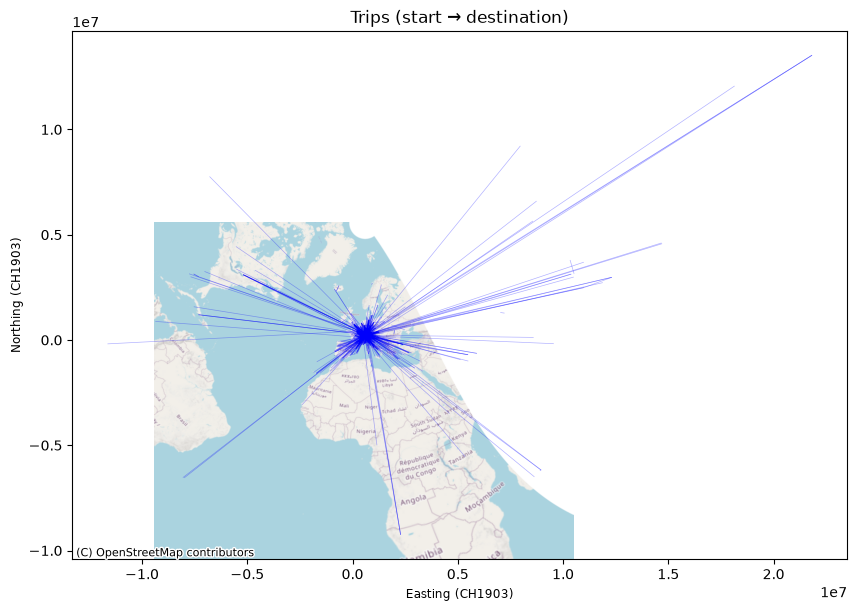

In [7]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import requests

file_path_trips = "./microcensus/dataset/wegeinland.csv"
file_path_etappen = "./microcensus/dataset/etappen.csv"

# Global session for gjenbruk av TCP-forbindelser
session = requests.Session()


def fetch_height(coord):
    """Henter høyde for et enkelt koordinatpar (easting, northing)."""
    easting, northing = coord
    if pd.isna(easting) or pd.isna(northing):
        return coord, None
    url = f"https://api3.geo.admin.ch/rest/services/height?easting={easting}&northing={northing}&sr=21781"
    try:
        response = session.get(url, timeout=10)
        return coord, float(response.json()["height"])
    except Exception as e:
        print(f"Feil ved henting for {coord}: {e}")
        return coord, None


# 1. Les inn data
trips_df = pd.read_csv(file_path_trips, encoding="latin1")

# 2. Samle ALLE unike koordinatpar fra begge dataframes
unique_coords = set(zip(trips_df["S_X_CH1903"], trips_df["S_Y_CH1903"]))

print(f"Totalt antall unike koordinater å hente: {len(unique_coords)}")

# 3. Hent høyder i parallell med tråder (f.eks. 20 samtidige tråder)
height_map = {}
with ThreadPoolExecutor(max_workers=20) as executor:
    results = executor.map(fetch_height, unique_coords)
    for coord, height in results:
        height_map[coord] = height

# 4. Map resultatene tilbake på dataframene
trips_df["S_Z_CH1903"] = [
    height_map.get((x, y))
    for x, y in zip(trips_df["S_X_CH1903"], trips_df["S_Y_CH1903"])
]
trips_df["Z_Z_CH1903"] = [
    height_map.get((x, y))
    for x, y in zip(trips_df["Z_X_CH1903"], trips_df["Z_Y_CH1903"])
]


# 5. Lagre resultatene permanent
trips_df.to_csv(file_path_trips, index=False)

print("Ferdig! Høyder er beregnet og lagret.")

Totalt antall unike koordinater å hente: 105035


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_4155/3432060114.py:42: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  trips_df["S_Z_CH1903"] = [
/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_4155/3432060114.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  trips_df["Z_Z_CH1903"] = [


Ferdig! Høyder er beregnet og lagret.
